# Thesis Fig. 8 — online kernel learning recovers the Wiener-optimal kernel

Reproduction of Tepper (2026), Fig. 8 (thesis PDF p. 103; printed p. 96), panel by panel.

> Starting from a broad Gaussian, the online update (eq. 9.10) reshapes the travelling bump and moves its spectral
> allocation to the Wiener solution, while the readout weights re-equilibrate quickly inside each slower kernel epoch.

**Panels:** A translated bump activity (initial, epoch 100, final) · B centred kernel shape · C kernel spectrum ·
D fast weight equilibration within kernel epochs · E slow kernel convergence across kernel epochs.

**Acceptance (spec 6A.6):** allocation within 5% of eq. 7.13 on active modes; active set exact; readout at ridge
equilibrium within each kernel step.

**Parameters [D11]:** `configs/thesis/fig8.yaml` (inferred from the figure; see comments there). The kernel rule is
eq. 9.10 **as written** (no preconditioner): in this regime the stiffness ratio ((a+λ)/λ)⁴ is only ~10³ (REPORT
discrepancy 4), so the literal rule converges. The fast loop is the mean-field delta rule, 20 sweeps per kernel epoch,
warm-started. The per-mode error is the spatial DFT of each epoch's readout errors.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seqnet.thesis as th
from seqnet.thesis.figures import load_config, save_data, load_data, save_figure, record_checks, style

style()
FIG = "fig8"
cfg = load_config(FIG)
N = cfg["N"]; lam = N * cfg["decay_unitary"]; K0 = N * cfg["K0_unitary"]
tg = cfg["target"]
S = th.TargetClass.narrowband(N // 2, xi0=tg["xi0"], ell=tg["ell"]).psd.copy(); S[-1] = 0.0  # drop Nyquist
tc = th.TargetClass(psd=S, name="narrowband")
mult = th.mode_multiplicity(N)
ik = cfg["initial_kernel"]
a0 = th.Kernel.from_family(ik["family"], N, sigma=ik["sigma"]).alloc(); a0 *= K0 / np.sum(mult * a0)
ref = th.water_fill(S, lam, K0, N=N)
eta_k = cfg["eta_k_factor"] * lam**2 / (3 * S.max())
eta_w = cfg["eta_w_factor"] / (a0.max() / N + lam / N)
rule = th.ThesisKernelRule(eta=eta_k, decay=lam, N=N, K0=K0, budget=cfg["budget"])
ls = th.LearningSystem(N=N, decay=lam, K0=K0, target=tc, a0=a0, rule=rule, readout=cfg["readout"], eta_w=eta_w,
                       inner_epochs=cfg["inner_epochs"], seed=cfg["seed"], record_inner=True)
h = ls.run(cfg["kernel_epochs"])
H = h.as_arrays()
A = H["alloc"]
save_data(FIG, "run", params={k: cfg[k] for k in cfg}, alloc=A, ref=ref.a, nu=H["nu"], readout_dist=H["readout_dist"],
          total_error=H["total_error"], inner_dist=H["inner_dist"], err_power=H["err_power"], S=S, lam=lam, K0=K0)
ref.M_star, ls.n_warnings

(18, 17)

## Panel A — translated bump activity

The bump x(c) = k(r − c) as it traverses the ring (rows: bump position over one traversal; columns: neurons),
peak-normalized, for the kernel at epoch 0, epoch 100 and the final epoch.

In [2]:
d = load_data(FIG, "run")
sched = th.Schedule(N, 1)
rasters = {}
for lab, e in [("initial", 0), ("epoch 100", 100), ("final", len(d["alloc"]) - 1)]:
    X = th.design_matrix(th.Kernel.from_alloc(d["alloc"][e], N), sched)
    rasters[lab] = X / np.abs(X).max()
save_data(FIG, "A_bump_rasters", **{k.replace(" ", "_"): v for k, v in rasters.items()})

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig8/A_bump_rasters.npz')

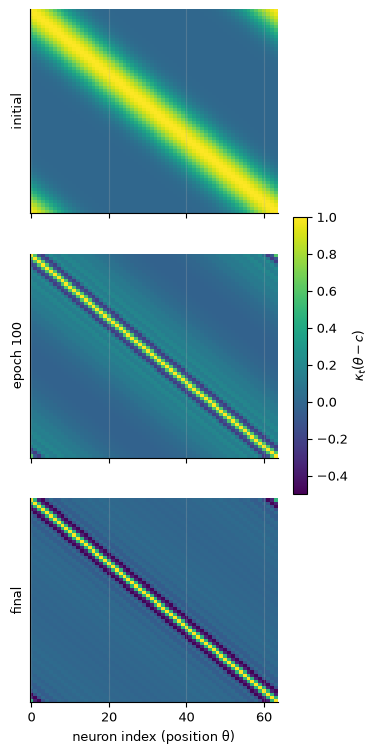

In [3]:
d = load_data(FIG, "A_bump_rasters")
fig, axs = plt.subplots(3, 1, figsize=(4, 9), sharex=True)
for ax, lab in zip(axs, ["initial", "epoch_100", "final"]):
    im = ax.imshow(d[lab], cmap="viridis", aspect="auto", vmin=-0.5, vmax=1); ax.set_ylabel(lab.replace("_", " ")); ax.set_yticks([])
axs[-1].set_xlabel("neuron index (position θ)"); fig.colorbar(im, ax=axs, shrink=0.4, label=r"$\kappa_t(\theta-c)$")
save_figure(FIG, "A_bump_rasters", fig); plt.show()

## Panel B — centred kernel shape over kernel epochs (peak-normalized), with the Wiener kernel

In [4]:
d = load_data(FIG, "run")
snaps = np.array(cfg["snapshots"])
r = th.Ring(N).centred_positions
Ks = np.stack([th.Kernel.from_alloc(d["alloc"][e], N).values for e in snaps])
Kw = th.Kernel.from_alloc(d["ref"], N).values
save_data(FIG, "B_kernel_shape", r=r, K=Ks, K_wiener=Kw, epochs=snaps)

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig8/B_kernel_shape.npz')

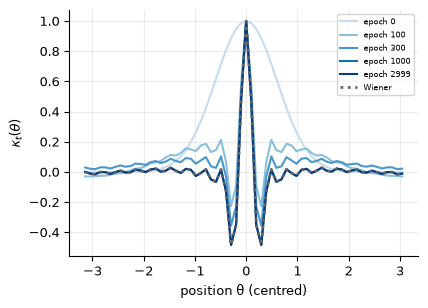

In [5]:
d = load_data(FIG, "B_kernel_shape"); o = np.argsort(d["r"])
fig, ax = plt.subplots(figsize=(4.5, 3.2))
cols = plt.cm.Blues(np.linspace(0.25, 0.95, len(d["epochs"])))
for k, e, col in zip(d["K"], d["epochs"], cols):
    ax.plot(d["r"][o], k[o] / k.max(), color=col, label=f"epoch {e}")
ax.plot(d["r"][o], d["K_wiener"][o] / d["K_wiener"].max(), ":", color="0.4", lw=2, label="Wiener")
ax.set_xlabel("position θ (centred)"); ax.set_ylabel(r"$\kappa_t(\theta)$"); ax.legend(fontsize=6)
save_figure(FIG, "B_kernel_shape", fig); plt.show()

## Panel C — kernel spectrum a_m (thesis units a/N): initial, final, Wiener (eq. 7.13)

In [6]:
d = load_data(FIG, "run")
save_data(FIG, "C_spectrum", m=np.arange(N // 2 + 1), initial=d["alloc"][0] / N, final=d["alloc"][-1] / N, wiener=d["ref"] / N)

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig8/C_spectrum.npz')

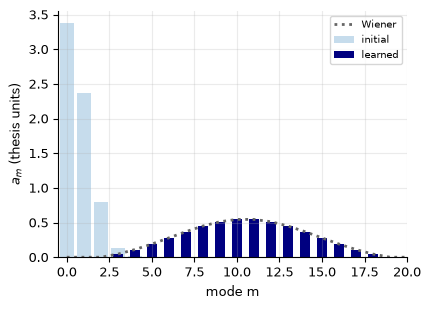

In [7]:
d = load_data(FIG, "C_spectrum")
fig, ax = plt.subplots(figsize=(4.5, 3.2))
ax.bar(d["m"], d["initial"], color="tab:blue", alpha=0.25, label="initial")
ax.bar(d["m"], d["final"], color="navy", width=0.6, label="learned")
ax.plot(d["m"], d["wiener"], ":", color="0.4", lw=2, label="Wiener")
ax.set_xlim(-0.5, 20); ax.set_xlabel("mode m"); ax.set_ylabel(r"$a_m$ (thesis units)"); ax.legend(fontsize=7)
save_figure(FIG, "C_spectrum", fig); plt.show()

## Panel D — fast weight equilibration: |w − w*(a_t)|/|w*(a_t)| over the 20 sweeps of selected kernel epochs

In [8]:
d = load_data(FIG, "run")
pick = np.array([0, 1, 3, 10, 30, 100, 1000, len(d["inner_dist"]) - 1])
save_data(FIG, "D_fast_weights", epochs=pick, inner=d["inner_dist"][pick])

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig8/D_fast_weights.npz')

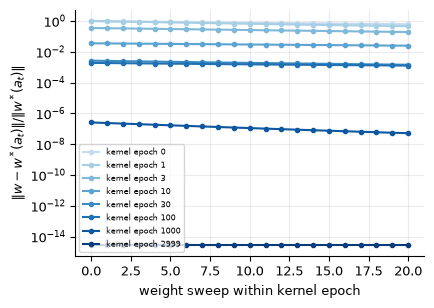

In [9]:
d = load_data(FIG, "D_fast_weights")
fig, ax = plt.subplots(figsize=(4.5, 3.2))
cols = plt.cm.Blues(np.linspace(0.25, 0.95, len(d["epochs"])))
for e, tr, col in zip(d["epochs"], d["inner"], cols):
    ax.semilogy(tr, "o-", ms=3, color=col, label=f"kernel epoch {e}")
ax.set_xlabel("weight sweep within kernel epoch"); ax.set_ylabel(r"$\|w-w^*(a_t)\|/\|w^*(a_t)\|$"); ax.legend(fontsize=6)
save_figure(FIG, "D_fast_weights", fig); plt.show()

## Panel E — slow kernel, fast weights

Relative distance of the allocation to the Wiener allocation, ‖a_t − a*‖/‖a*‖, and of the readout (after its inner
loop) to its ridge optimum, across kernel epochs.

In [10]:
d = load_data(FIG, "run")
dist_a = np.linalg.norm(d["alloc"] - d["ref"], axis=1) / np.linalg.norm(d["ref"])
save_data(FIG, "E_slow_fast", dist_a=dist_a, readout_dist=d["readout_dist"])

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig8/E_slow_fast.npz')

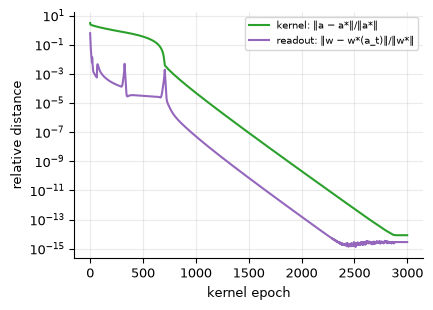

In [11]:
d = load_data(FIG, "E_slow_fast")
fig, ax = plt.subplots(figsize=(4.5, 3.2))
ax.semilogy(d["dist_a"], color="tab:green", label="kernel: ‖a − a*‖/‖a*‖")
ax.semilogy(d["readout_dist"], color="tab:purple", label="readout: ‖w − w*(a_t)‖/‖w*‖")
ax.set_xlabel("kernel epoch"); ax.set_ylabel("relative distance"); ax.legend(fontsize=7)
save_figure(FIG, "E_slow_fast", fig); plt.show()

## Acceptance

In [12]:
d = load_data(FIG, "run"); e = load_data(FIG, "E_slow_fast")
a, ar = d["alloc"][-1], d["ref"]
act = ar > 0
rel = float(np.max(np.abs(a[act] - ar[act]) / ar[act]))
learned_act = a > 1e-9 * a.max()
checks = [
    {"item": "allocation within 5% of eq. 7.13 on active modes", "criterion": "max relative error < 0.05", "value": rel, "passed": rel < 0.05},
    {"item": "active set exact", "criterion": "identical masks", "value": {"learned": np.nonzero(learned_act)[0], "wiener": np.nonzero(act)[0]},
     "passed": bool(np.array_equal(learned_act, act))},
    {"item": "readout at ridge equilibrium within each kernel step", "criterion": "readout distance < 1e-2 after the inner loop, from epoch 10 on",
     "value": float(e["readout_dist"][10:].max()), "passed": bool(e["readout_dist"][10:].max() < 1e-2)},
]
bad = np.nonzero(e["readout_dist"] >= 1e-2)[0]
na = (d["alloc"] > 1e-9 * d["alloc"].max(axis=1, keepdims=True)).sum(1)
changes = np.nonzero(np.diff(na))[0] + 1
checks.append({"item": "epochs violating readout equilibrium (diagnostic)", "criterion": "reported only",
               "value": {"n_epochs": int(bad.size), "fraction": float(bad.size / e["readout_dist"].size), "epochs": bad,
                         "active_set_changes_at": changes}, "passed": None})
record_checks(FIG, checks)
for c in checks: print(c)

{'item': 'allocation within 5% of eq. 7.13 on active modes', 'criterion': 'max relative error < 0.05', 'value': 2.7466809413372068e-14, 'passed': True}
{'item': 'active set exact', 'criterion': 'identical masks', 'value': {'learned': array([ 3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18]), 'wiener': array([ 3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18])}, 'passed': True}
{'item': 'readout at ridge equilibrium within each kernel step', 'criterion': 'readout distance < 1e-2 after the inner loop, from epoch 10 on', 'value': 0.025028701595882753, 'passed': False}
{'item': 'epochs violating readout equilibrium (diagnostic)', 'criterion': 'reported only', 'value': {'n_epochs': 17, 'fraction': 0.005666666666666667, 'epochs': array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 19, 20]), 'active_set_changes_at': array([  1,   2,   3,   6,  20,  65, 326, 706])}, 'passed': None}
